In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
%matplotlib inline

In [35]:
df = pd.read_csv("1-studyhours.csv")

In [36]:
df.describe()

,Study Hours,Exam Score
count,33.000000,33.000000
mean,15.772727,74.612121
std,7.608723,18.711206
min,3.000000,40.000000
25%,9.600000,58.500000
50%,17.400000,78.800000
75%,21.300000,90.800000
max,30.000000,100.000000


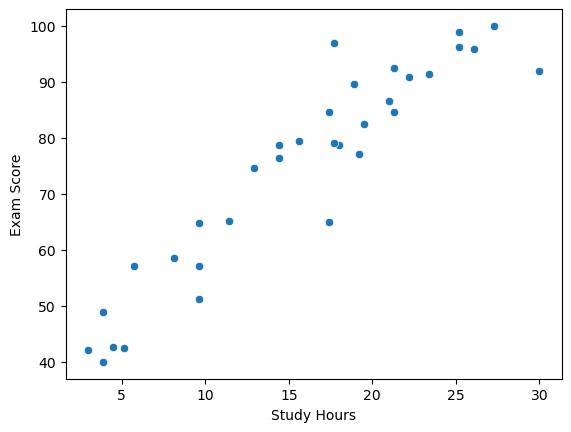

In [37]:
sns.scatterplot(data=df, x="Study Hours", y="Exam Score")
plt.show()

In [38]:
# independent and dependent features
X = df[["Study Hours"]] # X değeri pandas Series olarak değil de DataFrame olarak verilmesi lazım. Çünkü birden fazla girdi olur genelde. Çift parantez olarak verilerek bu durum gerçekleştirilebilir. 
y = df["Exam Score"] # y değeri pandas Series olarak verilir.

In [39]:
type(X)

pandas.core.frame.DataFrame

In [40]:
type(y)

pandas.core.series.Series

In [41]:
# train-test split

from sklearn.model_selection import train_test_split

In [42]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=15)

In [43]:
y_train

18     64.9
1      57.1
2      42.7
32     89.6
6      77.1
3      65.1
29     82.4
26     64.8
9      84.6
4      78.7
28     79.1
10     92.4
27     79.5
13    100.0
17     74.7
15     97.0
22     76.5
31     96.2
11     95.9
7      90.8
0      40.0
23     42.2
5      78.8
12     92.0
21     58.5
8      99.0
Name: Exam Score, dtype: float64

In [44]:
y_test

25    42.4
14    86.6
30    91.5
16    57.2
24    51.2
20    49.0
19    84.7
Name: Exam Score, dtype: float64

In [45]:
# standardization (kolonlardaki verilerin etkilerini daha adil dağıtmak için. Kolonlardaki büyük sıçramalar Gradient Descent algoritmasını bozabilir.)
# balanced feature values, efficient gradient descent
# l1, l2
from sklearn.preprocessing import StandardScaler

In [46]:
df.head() 

,Study Hours,Exam Score
0,3.9,40.0
1,9.6,57.1
2,4.5,42.7
3,11.4,65.1
4,14.4,78.7


In [47]:
scaler = StandardScaler()

In [48]:
X_train = scaler.fit_transform(X_train) # fit deyince mü ve std buluyor. Transform yapınca o parametreleri yazıp z'yi dönüştürüyor.
X_test = scaler.transform(X_test) # fit --> data leakage. Train datasında hesapladıklarmızı kullanıyor çünkü test datasının verilerini bilmek istemiyoruz zaten.

In [49]:
X_train

array([[ 0.11794385],
       [-0.97424848],
       [-1.68837424],
       [ 0.32798083],
       [ 0.36998823],
       [-0.7222041 ],
       [ 0.41199563],
       [-0.97424848],
       [ 0.11794385],
       [-0.30213013],
       [ 0.15995124],
       [ 0.66404001],
       [-0.13410054],
       [ 1.50418796],
       [-0.51216711],
       [ 0.15995124],
       [-0.30213013],
       [ 1.21013618],
       [ 1.33615837],
       [ 0.7900622 ],
       [-1.77238903],
       [-1.89841122],
       [ 0.20195864],
       [ 1.88225453],
       [-1.18428547],
       [ 1.21013618]])

In [50]:
X_test

array([[-1.60435944],
       [ 0.62203261],
       [ 0.95809179],
       [-1.52034465],
       [-0.97424848],
       [-1.77238903],
       [ 0.66404001]])

In [51]:
from sklearn.linear_model import LinearRegression

In [52]:
regression = LinearRegression()

In [53]:
regression.fit(X=X_train, y=y_train)

LinearRegression()

In [54]:
print(f"regression coefficient: {regression.coef_}\nregression intercept: {regression.intercept_}")

regression coefficient: [16.17860223]
regression intercept: 76.9076923076923


In [60]:
regression.predict(scaler.transform([[10]]))

D:\Anaconda\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([62.05187491])

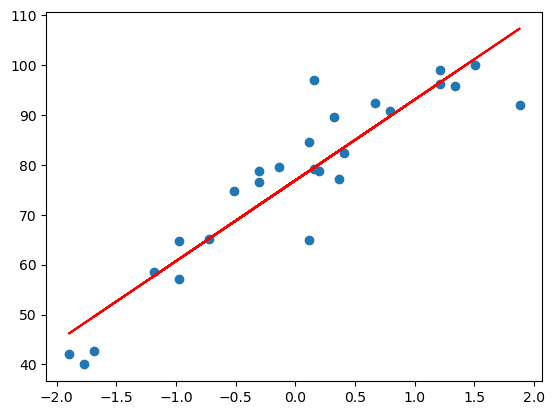

In [71]:
plt.scatter(x=X_train, y=y_train)
plt.plot(X_train, regression.predict(X_train), color="r") # aynı ölçeklendirmede kalsın diye X_train'i x ekseni olarak yazdık diye düşünüyorum.
plt.show()

In [72]:
# prediction with test data

In [75]:
y_pred_test = regression.predict(X_test)

In [76]:
type(X_test)

numpy.ndarray

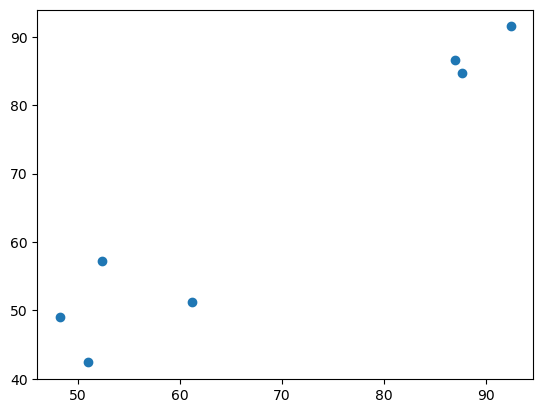

In [79]:
plt.scatter(y_pred_test, y_test)
plt.show()

In [80]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [81]:
mse = mean_squared_error(y_test, y_pred_test)
mae = mean_absolute_error(y_test, y_pred_test)
rmse = np.sqrt(mse)
print("mse:", mse)
print("mae:", mae)
print("rmse:", rmse)

mse: 29.45839048833392
mae: 4.054868128856142
rmse: 5.427558427906043


In [82]:
r2_score = r2_score(y_test, y_pred_test)
print("r2 score:", r2_score)

r2 score: 0.9196596206825491
